# 01 · Data Understanding
**CIS 517 – Hotel Booking Cancellation Prediction Using Data Mining**

Goal: load the Hotel Booking Demand dataset and understand its size, attributes and data types.

ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ

### 1. Import libraries
We use **pandas** to load and manipulate the data as a table (DataFrame) and **NumPy** for numerical operations.
The display option shows all 32 columns instead of hiding some of them.

In [3]:
import pandas as pd
import numpy as np

### 2. Load the dataset
The raw file is read from `data/raw/` and is **never modified**; cleaned versions will be saved to `data/processed/`.
We check the size of the dataset and preview the first five bookings.

In [4]:
df = pd.read_csv("../data/raw/hotel_bookings.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 119390
Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 3. Data types and missing values
`info()` lists every attribute with its data type and the number of non-missing values.
Any column with fewer than 119,390 non-null values contains missing values.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

### 4. Numeric vs. categorical attributes
We separate numeric and categorical attributes because each type is handled differently later:
numeric attributes are summarised, scaled and checked for outliers, while categorical attributes are counted and encoded.

In [6]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print(f"Numeric ({len(numeric_cols)}):", numeric_cols)
print()
print(f"Categorical ({len(categorical_cols)}):", categorical_cols)

Numeric (20): ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical (12): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


### 5. Missing values
Count and percentage of missing values per attribute (only attributes with at least one missing value are shown).
The percentage helps decide the treatment: fill a few missing values, or drop / transform an attribute that is mostly empty.

In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    "missing": missing,
    "percent": (missing / len(df) * 100).round(2)
})
missing_table

,missing,percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


### 6. Descriptive statistics (numeric attributes)
Summary statistics for every numeric attribute: count, mean, standard deviation, minimum, quartiles and maximum.
Unusual minimums or maximums point to invalid values and outliers that must be handled in preprocessing.

In [8]:
df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


### 7. Categorical attributes
Number of distinct values (cardinality) of each categorical attribute.
High-cardinality attributes (many distinct values) need special treatment before encoding.

In [9]:
df[categorical_cols].nunique().sort_values(ascending=False)

reservation_status_date    926
country                    177
arrival_date_month          12
assigned_room_type          12
reserved_room_type          10
market_segment               8
meal                         5
distribution_channel         5
customer_type                4
deposit_type                 3
reservation_status           3
hotel                        2
dtype: int64

### 8. Value distribution of key categorical attributes
Frequency and percentage of each value for the main categorical attributes.

In [10]:
for col in ["hotel", "deposit_type", "market_segment", "customer_type", "meal"]:
    counts = df[col].value_counts()
    percent = df[col].value_counts(normalize=True).mul(100).round(1)
    print(f"--- {col} ---")
    print(pd.DataFrame({"count": counts, "percent": percent}))
    print()

--- hotel ---
              count  percent
hotel                       
City Hotel    79330     66.4
Resort Hotel  40060     33.6

--- deposit_type ---
               count  percent
deposit_type                 
No Deposit    104641     87.6
Non Refund     14587     12.2
Refundable       162      0.1

--- market_segment ---
                count  percent
market_segment                
Online TA       56477     47.3
Offline TA/TO   24219     20.3
Groups          19811     16.6
Direct          12606     10.6
Corporate        5295      4.4
Complementary     743      0.6
Aviation          237      0.2
Undefined           2      0.0

--- customer_type ---
                 count  percent
customer_type                  
Transient        89613     75.1
Transient-Party  25124     21.0
Contract          4076      3.4
Group              577      0.5

--- meal ---
           count  percent
meal                     
BB         92310     77.3
HB         14463     12.1
SC         10650      8.9
Undef

### 9. Target attribute: `is_canceled`
Distribution of the class label we want to predict (0 = not canceled, 1 = canceled).
A strongly imbalanced target would make accuracy misleading, so we check the balance first.

Matplotlib is building the font cache; this may take a moment.


is_canceled
0    75166
1    44224
Name: count, dtype: int64

Cancellation rate: 37.0%


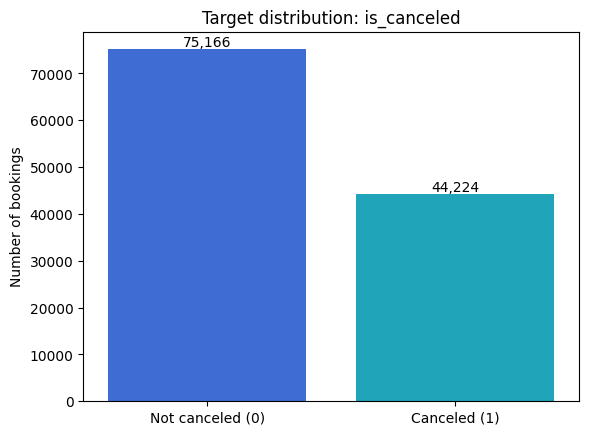

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

target = df["is_canceled"].value_counts().sort_index()
print(target)
print(f"\nCancellation rate: {df['is_canceled'].mean():.1%}")

ax = sns.countplot(data=df, x="is_canceled", hue="is_canceled", palette=["#2563eb", "#06b6d4"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Not canceled (0)", "Canceled (1)"])
ax.set_xlabel("")
ax.set_ylabel("Number of bookings")
ax.set_title("Target distribution: is_canceled")
for bar in ax.patches:
    ax.annotate(f"{int(bar.get_height()):,}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")
plt.show()

### 10. Duplicate records
Number of rows that are exact copies of another row (identical on all 32 attributes).

In [12]:
dup_count = df.duplicated().sum()
print(f"Exact duplicate rows: {dup_count:,} ({dup_count / len(df):.1%} of the data)")

Exact duplicate rows: 31,994 (26.8% of the data)


ــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــــ

## Summary of findings

**Dataset:** 119,390 bookings × 32 attributes (20 numeric, 12 categorical) from two hotels in Portugal
(City Hotel 66%, Resort Hotel 34%), with arrival dates from 2015 to 2017.

**Target:** `is_canceled` — 37.0% of bookings were canceled. A model that always predicts
"not canceled" would already reach 63.0% accuracy (baseline), so we will also use precision, recall and F1.

| Finding | Evidence | Action in preprocessing |
| --- | --- | --- |
| Duplicate records | 31,994 exact duplicate rows (26.8%) | Investigate and remove |
| Mostly empty attribute | `company` missing in 94.3% of rows | Replace with a flag: has_company (0/1) |
| Missing values | `agent` 13.7%, `country` 0.4%, `children` 4 rows | agent → has_agent flag; fill country and children |
| Invalid values | negative `adr` (−6.38); bookings with 0 guests or 0 nights | Remove invalid records |
| Extreme value | `adr` maximum of 5,400 while 75% of rates are below ~126 | Check and remove if it is an error |
| Duplicate category labels | `meal`: "Undefined" and "SC" both mean no meal | Merge into one value |
| High cardinality | `country` has 177 distinct values | Group rare countries before encoding |
| Data leakage | `reservation_status` and its date reveal the outcome | Exclude from the classification model |

**Next step:** `02_preprocessing.ipynb` — apply these actions and save the cleaned dataset to `data/processed/`.